1.7999999999999985 1e-323
1.7999999999999987 -1e-323
1.9999999999999987 1e-323
4.9999999999999964 -1e-323
6.000000000000003 -1e-323


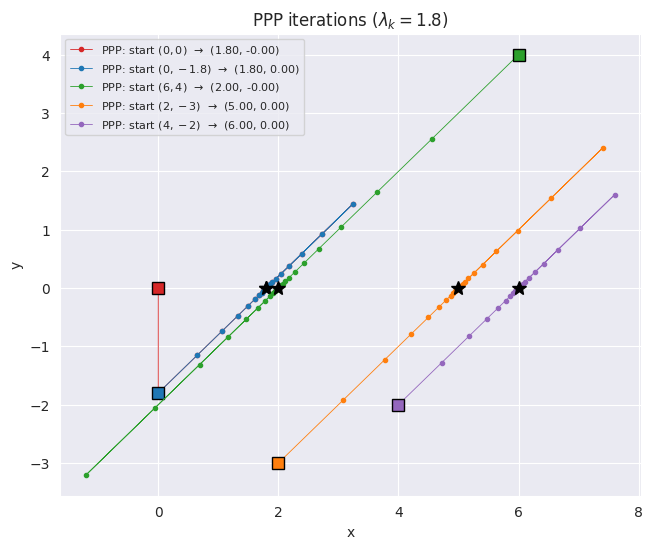

3.0013997200559808 0.0017996400719856027
3.0015596880623874 0.0017996400719856027
3.0015996800639972 0.0017996400719856027
3.002199560087982 0.0017996400719856027
3.0023995200959797 0.0017996400719856027


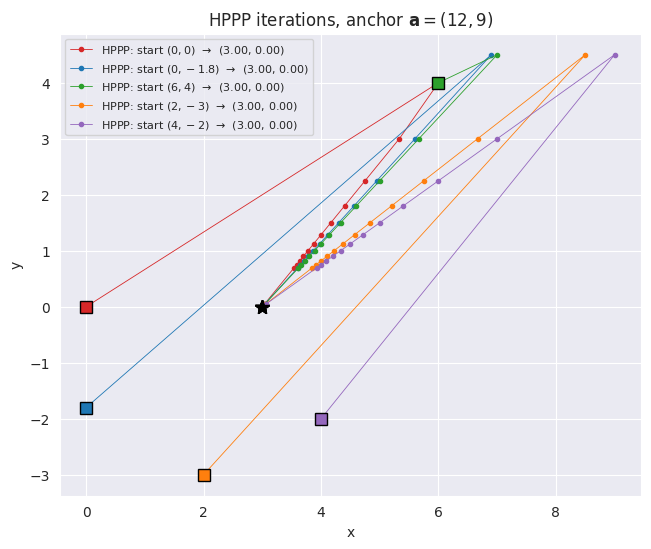

In [1]:
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import matplotlib as mlt
import seaborn as sns  # Import seaborn
import math
import os
# os.chdir('/MDL_img')
sns.set_style('darkgrid')  # Use seaborn to set the style
def F_fun(x):
    if x<=0:
        return 1-2*x
    elif 0< x <1:
        return 1-x
    else:
        return 0

def f(x):
    if x<=0:
        return -x
    else:
        return 0
def f2(x):
    if x<=0:
        return x**2
    elif 0<x<1:
        return 0
    else:
        return (x-1)**2

def g_star(y):
    if -1<=y<=0:
        return y
    else:
        return 1e8

def g_star2(y):
    if -1<=y<=0:
        return 0
    else:
        return 1e8

def prox_f(x):
    if x>0:
        return x
    elif x<-1:
        return x+1
    else:
        return 0

def prox_f2(x):
    if x<=0:
        return x/3
    elif x>=1:
        return (x+2)/3
    else:
        return x

def prox_gstar(x):
    if x<0:
        return -1
    elif x>1:
        return 0
    else:
        return x-1

def prox_gstar2(x):
    if -1<=x<=0:
        return x
    elif x<-1:
        return -1
    else:
        return 0

def Halpern_PPP_method(x0, y0,x_a, y_a, N):
    x, y = x0,y0
    x_cor =[]
    y_cor =[]
    res = []
    for k in range(N):
        x_cor.append(x0)
        y_cor.append(y0)
        mu = 1/(k+2)
        x = mu*x_a+ (1-mu)*prox_f(x0-y0)
        y = mu*y_a + (1-mu)*prox_gstar(2*(x-mu*x_a)/(1-mu)-x0+y0)
        x0, y0 = (x, y)
#         ax.plot(x, y, color='blue', alpha=0.1)
#         print(x,y)
        c = (x-y-(x_a-y_a))**2
        # x_cor.append(x)
        # y_cor.append(y)
        res.append(c)
    print(x,y)
    return x_cor,y_cor


def PPP_method(x0, y0, N):
    x_cor =[]
    y_cor =[]
    for k in range(N):
        x_cor.append(x0)
        y_cor.append(y0)
        x = prox_f(x0-y0)
        y = prox_gstar(2*x-x0+y0)
        x0, y0 = (x, y)
    print(x,y)
    return x_cor,y_cor

def relaxed_PPP_method(x0, y0, N, lam=0.5):
    x_cor =[]
    y_cor =[]
    for k in range(N):
        x_cor.append(x0)
        y_cor.append(y0)
        d = prox_f(x0-y0)
        x = lam*d + (1-lam)*x0
        y = lam*prox_gstar(2*d-x0+y0)+(1-lam)*y0
        x0, y0 = (x, y)
    print(x,y)
    return x_cor,y_cor

def select_HPPP_points(x_cor,y_cor, start=12, every=200):
    x_cor = np.array(x_cor)
    y_cor = np.array(y_cor)

    x_selected = x_cor[:start]
    y_selected = y_cor[:start]


    x_sparse = x_cor[start::every]
    y_sparse = y_cor[start::every]


    x_final = np.concatenate((x_selected, x_sparse))
    y_final = np.concatenate((y_selected, y_sparse))
    return x_final, y_final

# ---------- plotting for several starting points ----------
starts = [(0.0, 0.0), (0.0, -1.8), (6.0, 4.0), (2.0, -3.0), (4.0, -2.0)]   # 5 starting points
colors = ['tab:red', 'tab:blue', 'tab:green', 'tab:orange', 'tab:purple']
lam   = 1.8                # relaxation parameter lambda_k
anchor = (12.0, 9.0)       # (x_a, y_a) for HPPP
N_ppp  = 5000
N_hppp = 5000


def plot_trajectories(trajs, labels, title, fname=None):
    fig, ax = plt.subplots(figsize=(7.5, 6))
    for (xs, ys), c, lab in zip(trajs, colors, labels):
        ax.plot(xs, ys, '-o', color=c, lw=0.6, ms=3,
                label=f'{lab}  →  ({xs[-1]:.2f}, {ys[-1]:.2f})')
        ax.plot(xs[0], ys[0], marker='s', color=c, ms=8, mec='k')   # starting point
        ax.plot(xs[-1], ys[-1], marker='*', color='k', ms=10)       # last stored iterate
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(title)
    ax.legend(fontsize=8)
    if fname:
        fig.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()

# ---------- Figure 1: PPP ----------
ppp_trajs, ppp_labels = [], []
for (x0, y0) in starts:
    xs, ys = relaxed_PPP_method(x0, y0, N_ppp, lam=lam)
    ppp_trajs.append((np.array(xs), np.array(ys)))
    ppp_labels.append(f'PPP: start $({x0:g},{y0:g})$')
plot_trajectories(ppp_trajs, ppp_labels,
                  f'PPP iterations ($\\lambda_k={lam:g}$)',
                  'ppp_multi_start.png')


# ---------- Figure 2: HPPP ----------
hppp_trajs, hppp_labels = [], []
for (x0, y0) in starts:
    xs, ys = Halpern_PPP_method(x0, y0, anchor[0], anchor[1], N_hppp)
    xs, ys = select_HPPP_points(xs, ys, start=12, every=200)   # thin out the slow tail
    hppp_trajs.append((xs, ys))
    hppp_labels.append(f'HPPP: start $({x0:g},{y0:g})$')
plot_trajectories(hppp_trajs, hppp_labels,
                  f'HPPP iterations, anchor $\\mathbf{{a}}=({anchor[0]:g},{anchor[1]:g})$',
                  'hppp_multi_start.png')

1.0 -1.1102230246251565e-16
3.0005998800239975 0.0017996400719856027


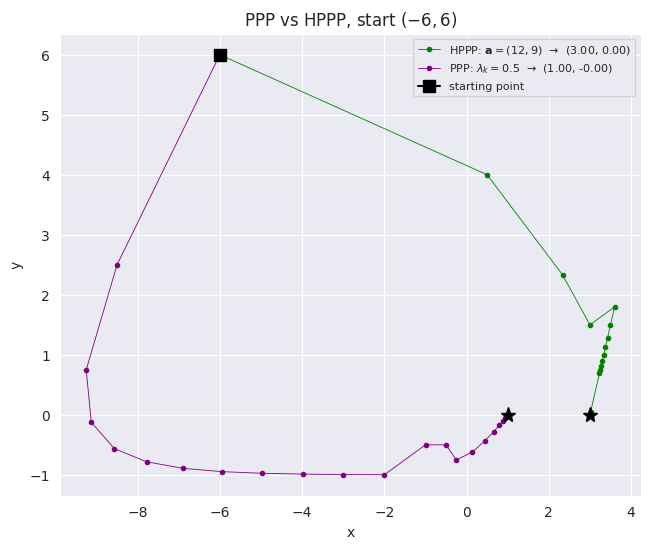

In [ ]:
# ---------- one starting point: PPP vs HPPP ----------
x_start, y_start = -6.0, 6.0       # the single starting point
anchor = (12.0, 9.0)              # anchor (x_a, y_a) for HPPP
lam    = 0.5                     # relaxation parameter of PPP
N_ppp  = 5000
N_hppp = 5000

# PPP (relaxed)
xp, yp = relaxed_PPP_method(x_start, y_start, N_ppp, lam=lam)
xp, yp = np.array(xp), np.array(yp)

# HPPP, thinned out because its tail is slow and dense
xh, yh = Halpern_PPP_method(x_start, y_start, anchor[0], anchor[1], N_hppp)
xh, yh = select_HPPP_points(xh, yh, start=12, every=200)

fig, ax = plt.subplots(figsize=(7.5, 6))

ax.plot(xh, yh, '-o', color='green', lw=0.6, ms=3,
        label=f'HPPP: $\\mathbf{{a}}=({anchor[0]:g},{anchor[1]:g})$  →  ({xh[-1]:.2f}, {yh[-1]:.2f})')
ax.plot(xp, yp, '-o', color='purple', lw=0.6, ms=3,
        label=f'PPP: $\\lambda_k={lam:g}$  →  ({xp[-1]:.2f}, {yp[-1]:.2f})')

ax.plot(x_start, y_start, marker='s', color='k', ms=9, label='starting point')   # shared start
ax.plot(xh[-1], yh[-1], marker='*', color='k', ms=11)                            # last iterates
ax.plot(xp[-1], yp[-1], marker='*', color='k', ms=11)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title(f'PPP vs HPPP, start $({x_start:g},{y_start:g})$')
ax.legend(fontsize=8)
fig.savefig('ppp_vs_hppp.png', dpi=300, bbox_inches='tight')
plt.show()

1.7999999999999985 1e-323
3.0013997200559808 0.0017996400719856027


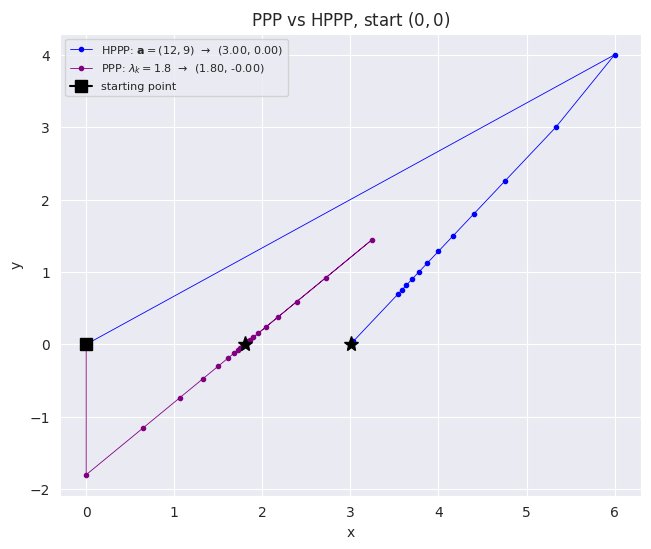

In [ ]:
# ---------- one starting point: PPP vs HPPP ----------
x_start, y_start = 0.0, 0.0       # the single starting point
anchor = (12.0, 9.0)              # anchor (x_a, y_a) for HPPP
lam    = 1.8                     # relaxation parameter of PPP
N_ppp  = 5000
N_hppp = 5000

# PPP (relaxed)
xp, yp = relaxed_PPP_method(x_start, y_start, N_ppp, lam=lam)
xp, yp = np.array(xp), np.array(yp)

# HPPP, thinned out because its tail is slow and dense
xh, yh = Halpern_PPP_method(x_start, y_start, anchor[0], anchor[1], N_hppp)
xh, yh = select_HPPP_points(xh, yh, start=12, every=200)

fig, ax = plt.subplots(figsize=(7.5, 6))

ax.plot(xh, yh, '-o', color='blue', lw=0.6, ms=3,
        label=f'HPPP: $\\mathbf{{a}}=({anchor[0]:g},{anchor[1]:g})$  →  ({xh[-1]:.2f}, {yh[-1]:.2f})')
ax.plot(xp, yp, '-o', color='purple', lw=0.6, ms=3,
        label=f'PPP: $\\lambda_k={lam:g}$  →  ({xp[-1]:.2f}, {yp[-1]:.2f})')

ax.plot(x_start, y_start, marker='s', color='k', ms=9, label='starting point')   # shared start
ax.plot(xh[-1], yh[-1], marker='*', color='k', ms=11)                            # last iterates
ax.plot(xp[-1], yp[-1], marker='*', color='k', ms=11)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title(f'PPP vs HPPP, start $({x_start:g},{y_start:g})$')
ax.legend(fontsize=8)
fig.savefig('ppp_vs_hppp.png', dpi=300, bbox_inches='tight')
plt.show()